# HDB resale data: exploratory analysis

This notebook profiles the original HDB resale CSVs for **January 2012–December 2017** and runs the January 2012 quality gate, lease derivation, and price anomaly heuristic. The CSVs in `../data/raw/` are the inputs and are never edited. Run cells from top to bottom; the merge cell writes the master and quarantined CSVs.

The January 2012 records supply exact allowed values for `town`, `flat_type`, `flat_model`, and `storey_range`. This is an assessment rule, not a claim that later values are wrong. Counts and charts below help assess its effect before further cleaning and transformation.


In [1]:
from pathlib import Path
from datetime import date
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Find Part 1 whether the kernel starts at the repository root or notebook folder.
candidates = [Path.cwd(), Path.cwd() / "part1_data_pipeline", Path.cwd().parent]
part1 = next(path for path in candidates if (path / "data" / "raw").is_dir())
raw_dir = part1 / "data" / "raw"
source_files = sorted(raw_dir.glob("*.csv"))
print(f"Part 1 directory found: {part1.name}")
print(f"Original CSV files found: {len(source_files)}")


Part 1 directory found: part1_data_pipeline
Original CSV files found: 4


## 1. Source inventory

Read the downloaded files in chunks so the exploratory step does not require loading the entire 2000–2026 collection at once. Keep only the assessment period in memory. `source_record_number` is the 1-based record position after each source header; it lets us trace a result back to the raw file.


In [2]:
frames = []
inventory = []
for path in source_files:
    total_rows = 0
    selected_rows = 0
    first_month, last_month = None, None
    columns = None
    for chunk in pd.read_csv(path, dtype="string", keep_default_na=False,
                             encoding="utf-8-sig", chunksize=50_000):
        columns = list(chunk.columns)
        first_month = min(first_month or chunk["month"].min(), chunk["month"].min())
        last_month = max(last_month or chunk["month"].max(), chunk["month"].max())
        chunk["source_record_number"] = range(total_rows + 1, total_rows + len(chunk) + 1)
        total_rows += len(chunk)
        selected = chunk.loc[chunk["month"].between("2012-01", "2017-12")].copy()
        if not selected.empty:
            selected["source_file"] = path.name
            frames.append(selected)
            selected_rows += len(selected)
    inventory.append({"source_file": path.name, "all_rows": total_rows,
                      "in_scope_rows": selected_rows, "columns": len(columns),
                      "first_month": first_month, "last_month": last_month})

raw = pd.concat(frames, ignore_index=True).fillna("")
display(pd.DataFrame(inventory))
print(f"In-scope records: {len(raw):,}; months: {raw['month'].nunique()}")


,source_file,all_rows,in_scope_rows,columns,first_month,last_month
0,ResaleFlatPricesBasedonApprovalDate2000Feb2012...,369651,3188,10,2000-01,2012-02
1,ResaleFlatPricesBasedonRegistrationDateFromJan...,37153,37153,11,2015-01,2016-12
2,ResaleFlatPricesBasedonRegistrationDateFromMar...,52203,52203,10,2012-03,2014-12
3,ResaleflatpricesbasedonregistrationdatefromJan...,242454,20509,11,2017-01,2026-10


In-scope records: 113,053; months: 72


The source schema changes in 2015 when `remaining_lease` appears. Missingness below includes earlier files where that column does not exist. A blank in the combined analysis therefore needs source context before it is called a data defect.

## 2. Completeness and repeated patterns

Count empty cells and distinct values across the selected period. Repeated combinations of source fields are *candidates* for duplicate review: the source has no transaction identifier, so identical published attributes do not prove two rows are the same sale.


In [3]:
profile = pd.DataFrame([
    {"column": column,
     "blank_rows": int(raw[column].eq("").sum()),
     "distinct_nonblank": int(raw.loc[raw[column].ne(""), column].nunique())}
    for column in raw.columns if column not in {"source_file", "source_record_number"}
])
display(profile)

common_source_columns = [column for column in raw.columns
                         if column not in {"remaining_lease", "source_file", "source_record_number"}]
print("Rows in repeated patterns across the ten common source fields:",
      int(raw.duplicated(subset=common_source_columns, keep=False).sum()))
print("Repeated rows beyond the first occurrence:",
      int(raw.duplicated(subset=common_source_columns, keep="first").sum()))


,column,blank_rows,distinct_nonblank
0,month,0,72
1,town,0,26
2,flat_type,0,7
3,block,0,2193
4,street_name,0,526
5,storey_range,0,25
6,floor_area_sqm,0,169
7,flat_model,0,20
8,lease_commence_date,0,50
9,resale_price,0,2865


Rows in repeated patterns across the ten common source fields: 902
Repeated rows beyond the first occurrence: 451


## 3. January 2012 authoritative values

These four allowlists come from the January 2012 source records. Matching is exact, including spelling, case, and spacing. The lists are shown to make the rule reviewable rather than hiding them in code.


In [4]:
reference_columns = ["town", "flat_type", "flat_model", "storey_range"]
january = raw.loc[raw["month"].eq("2012-01")]
reference = {column: set(january.loc[january[column].ne(""), column])
             for column in reference_columns}
print(f"January 2012 reference rows: {len(january):,}")
display(pd.DataFrame([
    {"field": column, "allowed_values": len(reference[column]),
     "values": ", ".join(sorted(reference[column]))}
    for column in reference_columns
]))


January 2012 reference rows: 1,559


,field,allowed_values,values
0,town,26,"ANG MO KIO, BEDOK, BISHAN, BUKIT BATOK, BUKIT ..."
1,flat_type,7,"1 ROOM, 2 ROOM, 3 ROOM, 4 ROOM, 5 ROOM, EXECUT..."
2,flat_model,13,"Adjoined flat, Apartment, Improved, Maisonette..."
3,storey_range,12,"01 TO 03, 04 TO 06, 07 TO 09, 10 TO 12, 13 TO ..."


## 4. Apply the strict rule

The production merge function reads the same original CSVs and writes accepted records to `data/master/` and failed records to `data/quarantined/`. Each quarantined row carries one reason per failed field. This cell is also the command needed to reproduce those two outputs from the notebook.


In [5]:
sys.path.insert(0, str(part1.resolve()))
from combine import combine

master_path = part1 / "data" / "master" / "resale_master_2012_2017.csv"
quarantine_path = part1 / "data" / "quarantined" / "resale_quarantined_2012_2017.csv"
result = combine(raw_dir, master_path, quarantine_path,
                 date(2012, 1, 1), date(2017, 12, 1))
master = pd.read_csv(master_path, dtype="string", keep_default_na=False)
quarantine = pd.read_csv(quarantine_path, dtype="string", keep_default_na=False)
summary = pd.DataFrame({"output": ["In scope", "Master", "Quarantined"],
                        "records": [len(raw), len(master), len(quarantine)]})
display(summary)
assert len(raw) == len(master) + len(quarantine)


,output,records
0,In scope,113053
1,Master,105225
2,Quarantined,7828


In [6]:
reason_counts = (quarantine["quarantine_reasons"].str.split("|", regex=False)
                 .explode().value_counts().rename_axis("reason").reset_index(name="rows"))
display(reason_counts)

monthly = raw.groupby("month").size().rename("raw_rows").to_frame()
monthly["master_rows"] = master.groupby("month").size()
monthly["quarantined_rows"] = quarantine.groupby("month").size()
monthly = monthly.fillna(0).astype(int)
monthly["quarantine_pct"] = (100 * monthly["quarantined_rows"] /
                              monthly["raw_rows"]).round(1)
print("Months with no accepted records:")
display(monthly.loc[monthly["master_rows"].eq(0)])


,reason,rows
0,invalid_storey_range,7050
1,invalid_flat_model,870


Months with no accepted records:


,raw_rows,master_rows,quarantined_rows,quarantine_pct
month,,,,
2012-03,2360,0,2360,100.0
2012-04,2155,0,2155,100.0
2012-05,2323,0,2323,100.0


The counts above are row counts per failed field, so a row that fails two fields appears in both totals. The table below shows the exact later values absent from January 2012 and how often they occur.

In [7]:
unseen = []
for column in reference_columns:
    counts = raw.loc[~raw[column].isin(reference[column]), column].value_counts()
    for value, count in counts.items():
        unseen.append({"field": column, "unseen_value": value, "rows": int(count)})
display(pd.DataFrame(unseen).sort_values(["field", "rows"], ascending=[True, False]))


,field,unseen_value,rows
0,flat_model,DBSS,583
1,flat_model,Type S1,179
2,flat_model,Type S2,78
3,flat_model,Improved-Maisonette,15
4,flat_model,Premium Maisonette,8
5,flat_model,Premium Apartment Loft,6
6,flat_model,2-room,1
7,storey_range,01 TO 05,2700
8,storey_range,06 TO 10,2474
9,storey_range,11 TO 15,1259


### Failure mechanisms and examples

The reason codes identify failed fields. To understand *why* `storey_range` failed, compare each range's width and upper floor with January 2012. The table below partitions quarantined rows by their primary mismatch; a row can still carry both field-level reasons.

In [8]:
reference_bounds = pd.Series(sorted(reference["storey_range"])).str.extract(
    r"(?P<lower>\d+) TO (?P<upper>\d+)"
).astype(int)
reference_widths = set(reference_bounds["upper"] - reference_bounds["lower"] + 1)
highest_reference_floor = int(reference_bounds["upper"].max())

failed_bounds = quarantine["storey_range"].str.extract(
    r"(?P<lower>\d+) TO (?P<upper>\d+)"
).astype("Int64")
failed_widths = failed_bounds["upper"] - failed_bounds["lower"] + 1
storey_failed = quarantine["quarantine_reasons"].str.contains(
    "invalid_storey_range", regex=False
)
mechanism = pd.Series("Flat model only", index=quarantine.index)
mechanism.loc[storey_failed] = "Other storey value outside reference"
mechanism.loc[storey_failed & ~failed_widths.isin(reference_widths)] = (
    "Different storey-band width"
)
mechanism.loc[storey_failed & failed_widths.isin(reference_widths)
              & failed_bounds["lower"].gt(highest_reference_floor)] = (
    "Above January 2012 floor coverage"
)
print(f"January reference widths: {sorted(reference_widths)} floors; "
      f"highest floor: {highest_reference_floor}")
display(mechanism.value_counts().rename_axis("mechanism").reset_index(name="rows"))
examples = quarantine.assign(mechanism=mechanism).groupby("mechanism", sort=False).head(1)
display(examples[["mechanism", "month", "flat_model", "storey_range",
                  "quarantine_reasons", "source_file", "source_record_number"]])


January reference widths: [3] floors; highest floor: 36


,mechanism,rows
0,Different storey-band width,6838
1,Flat model only,778
2,Above January 2012 floor coverage,212


,mechanism,month,flat_model,storey_range,quarantine_reasons,source_file,source_record_number
0,Above January 2012 floor coverage,2012-02,Improved,37 TO 39,invalid_storey_range,ResaleFlatPricesBasedonApprovalDate2000Feb2012...,369410
1,Different storey-band width,2012-03,Improved,06 TO 10,invalid_storey_range,ResaleFlatPricesBasedonRegistrationDateFromMar...,1
6841,Flat model only,2012-07,Improved-Maisonette,01 TO 03,invalid_flat_model,ResaleFlatPricesBasedonRegistrationDateFromMar...,9716


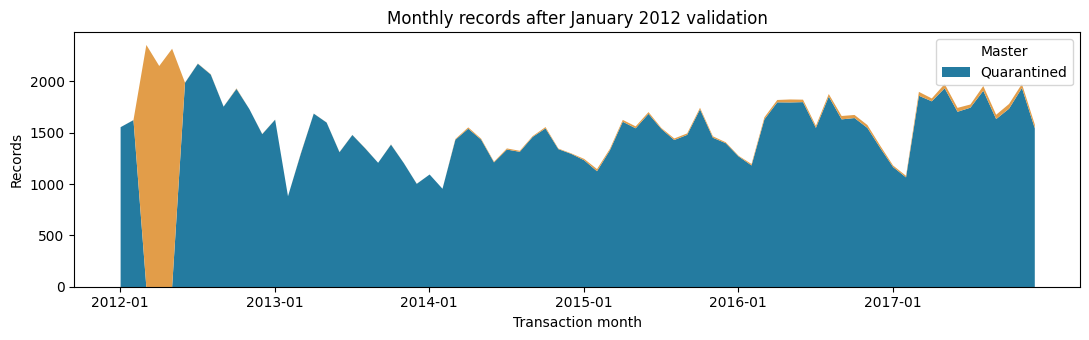

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.5))
monthly[["master_rows", "quarantined_rows"]].plot.area(ax=ax,
    color=["#247ba0", "#e29d49"], linewidth=0)
ax.set(title="Monthly records after January 2012 validation",
       xlabel="Transaction month", ylabel="Records")
ax.legend(["Master", "Quarantined"], loc="upper right")
ax.set_xticks(range(0, len(monthly), 12), monthly.index[::12], rotation=0)
plt.tight_layout()
plt.show()


## 5. Numeric behaviour for later quality rules

Inspect resale price, floor area, and price per square metre across the **in-scope raw records**. These summaries are descriptive; no anomaly threshold is applied here. A price-per-square-metre comparison is more useful than a single price threshold because flat sizes differ.


In [10]:
numeric = raw[["month", "town", "flat_type", "resale_price", "floor_area_sqm"]].copy()
numeric["price"] = pd.to_numeric(numeric["resale_price"], errors="coerce")
numeric["area_sqm"] = pd.to_numeric(numeric["floor_area_sqm"], errors="coerce")
numeric["price_per_sqm"] = numeric["price"] / numeric["area_sqm"].where(numeric["area_sqm"].gt(0))
numeric["year"] = numeric["month"].str[:4]
print("Non-numeric resale prices:", int(numeric["price"].isna().sum()))
print("Non-numeric or non-positive areas:",
      int((numeric["area_sqm"].isna() | numeric["area_sqm"].le(0)).sum()))
display(numeric.groupby("year")[["price", "price_per_sqm"]]
        .agg(["count", "median", "min", "max"]).round(2))


Non-numeric resale prices: 0
Non-numeric or non-positive areas: 0


price                                price_per_sqm                    \
      count    median       min        max         count   median      min   
year                                                                         
2012  23198  445000.0  209000.0  1010000.0         23198  4701.49   2375.0   
2013  16097  455000.0  208000.0  1050000.0         16097  4887.32   3059.7   
2014  16096  420000.0  195000.0  1088888.0         16096  4567.57  3055.12   
2015  17780  405000.0  195000.0  1088000.0         17780  4307.69  2686.57   
2016  19373  410000.0  190000.0  1150000.0         19373  4298.51  2788.46   
2017  20509  410000.0  175000.0  1180000.0         20509  4281.88  2611.94   

                
           max  
year            
2012  10410.26  
2013   9666.67  
2014   9473.68  
2015  10645.16  
2016  10566.04  
2017  10635.51

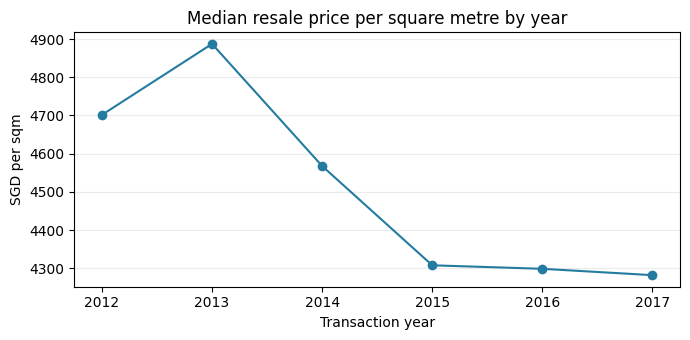

In [11]:
yearly_median = numeric.groupby("year")["price_per_sqm"].median()
fig, ax = plt.subplots(figsize=(7, 3.5))
yearly_median.plot(ax=ax, marker="o", color="#247ba0")
ax.set(title="Median resale price per square metre by year",
       xlabel="Transaction year", ylabel="SGD per sqm")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 6. Remaining lease on 1 January 2027

The source provides a lease commencement **year**, not a full date. Assume each 99-year lease starts on 1 January of that year. Count complete months to 1 January 2027, then express them as years and months. The source `remaining_lease` field is kept unchanged because it refers to the resale application date.

In [12]:
from lease import build_cleaned

cleaned_path = part1 / "data" / "cleaned" / "resale_cleaned_2012_2017.csv"
cleaned_count = build_cleaned(master_path, cleaned_path)
cleaned = pd.read_csv(cleaned_path, dtype="string", keep_default_na=False)
assert cleaned_count == len(master) == len(cleaned)
lease_years = cleaned["remaining_lease_2027_years"].astype(int)
lease_months = cleaned["remaining_lease_2027_months"].astype(int)
print(f"Cleaned records: {cleaned_count:,}")
print(f"Remaining lease: {lease_years.min()}–{lease_years.max()} years")
print(f"Records with nonzero calculated months: {lease_months.ne(0).sum():,}")
examples = pd.concat([cleaned.loc[cleaned["remaining_lease"].eq("")].head(1),
                      cleaned.loc[cleaned["remaining_lease"].ne("")].head(1)])
display(examples[["month", "lease_commence_date", "remaining_lease",
                  "remaining_lease_2027"]])


Cleaned records: 105,225
Remaining lease: 38–87 years
Records with nonzero calculated months: 0


,month,lease_commence_date,remaining_lease,remaining_lease_2027
0,2012-01,1979,,51 years 00 months
48432,2015-01,1986,70,58 years 00 months


## 7. Flag potential resale price anomalies

Compare log(resale price per square metre) within each transaction year, town, and flat type. A robust median/MAD score beyond ±3.5 flags a possible high or low price. Require at least 30 peer records and nonzero MAD; otherwise mark the row unassessed. This is a review flag, not a reason to discard a sale. Differences in age, floor, model, or condition may explain a flagged price.

In [13]:
from price_anomalies import flag_prices

cleaned = flag_prices(cleaned_path)
status_counts = cleaned["price_anomaly_status"].value_counts().rename_axis("status").reset_index(name="rows")
display(status_counts)
print(f"Potential anomalies: {cleaned['price_anomaly_flag'].eq('true').sum():,} of {len(cleaned):,} accepted sales")
display(cleaned.loc[cleaned["price_anomaly_flag"].eq("true"),
                    ["month", "town", "flat_type", "resale_price", "floor_area_sqm",
                     "price_per_sqm", "price_anomaly_robust_z", "price_anomaly_status"]]
        .sort_values("price_anomaly_robust_z", key=lambda s: pd.to_numeric(s), ascending=False)
        .head(5))

,status,rows
0,normal,102201
1,insufficient_peers,2269
2,high,675
3,low,80


Potential anomalies: 755 of 105,225 accepted sales


,month,town,flat_type,resale_price,floor_area_sqm,price_per_sqm,price_anomaly_robust_z,price_anomaly_status
79067,2016-09,BEDOK,3 ROOM,498000,62,8032.26,8.625,high
70269,2016-04,BEDOK,3 ROOM,498000,62,8032.26,8.625,high
78994,2016-09,ANG MO KIO,3 ROOM,570000,70,8142.86,8.054,high
14056,2012-11,KALLANG/WHAMPOA,3 ROOM,812000,78,10410.26,7.551,high
61585,2015-10,BEDOK,3 ROOM,478000,62,7709.68,7.380,high


## 8. Generate the Markdown profiling report

The report script repeats the measurements, verifies that every selected source record appears exactly once in master or quarantine, and checks source field values. Run this cell after the anomaly cell to recreate `DATA_PROFILING_REPORT.md`.

In [14]:
import subprocess

report_path = part1 / "DATA_PROFILING_REPORT.md"
subprocess.run([sys.executable, str(part1 / "profile.py")],
               check=True, capture_output=True, text=True)
print(f"Created {report_path.name} ({len(report_path.read_text().splitlines())} lines)")


Created DATA_PROFILING_REPORT.md (270 lines)


## Interpretation and next decisions

- The January 2012 reference contains **1,559 records**. Exact value matching yields **105,225 master records** and **7,828 quarantined records** from **113,053** in-scope records.
- `storey_range` explains most quarantines. **6,838 rows (87.4% of quarantine)** use five-floor bands confined to March–May 2012, while January uses three-floor bands. Another **212 rows** use bands above January's highest observed floor, 36. These may be valid transactions; quarantine means they fail the assessment's reference rule.
- **778 rows** fail only `flat_model`; **92 rows** fail both `flat_model` and `storey_range`. `DBSS`, `Type S1`, and `Type S2` account for most unseen flat-model values.
- The publication changes from approval date to registration date in March 2012. Trends across that boundary should be interpreted with that source change in mind.
- The source `remaining_lease` column appears only from 2015 and refers to the resale application date. The new as-of-**1 January 2027** calculation uses the commencement year for every accepted row. Under the documented 1 January start assumption, every calculated month component is zero; the actual start month is unavailable.
- Across the ten source fields common to all files, **902 rows** occur in repeated attribute patterns (**451** beyond the first occurrence). Identical published attributes do not establish duplicate transactions.
- The raw median resale price per square metre peaks in **2013** and declines through **2017** in this period. This is descriptive; flat mix and the source date-basis change affect comparisons.
- The peer-based robust price rule flags **675 high** and **80 low** prices; **2,269** rows lack enough peers for assessment. Flags are review leads, not proof of error. Accepted rows stay in the cleaned dataset.
